In [49]:
import pandas as pd
import seaborn as sns
import duckdb
import matplotlib.pyplot as plt
import plotly.express as px

In [2]:
olympics = pd.read_csv('data/olympics.csv')
olympics.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [5]:
athletes = duckdb.sql("""SELECT * FROM olympics 
                        WHERE Games = '2016 Summer' AND SEX = 'M'
                        AND (Sport = 'Basketball' OR Sport = 'Hockey' OR Sport = 'Gymnastics')""").df()
athletes.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Individual All-Around,NaN
1,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Floor Exercise,NaN
2,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Parallel Bars,NaN
3,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Horizontal Bar,NaN
4,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Rings,NaN


# Scatterplots

<Axes: xlabel='Height', ylabel='Weight'>

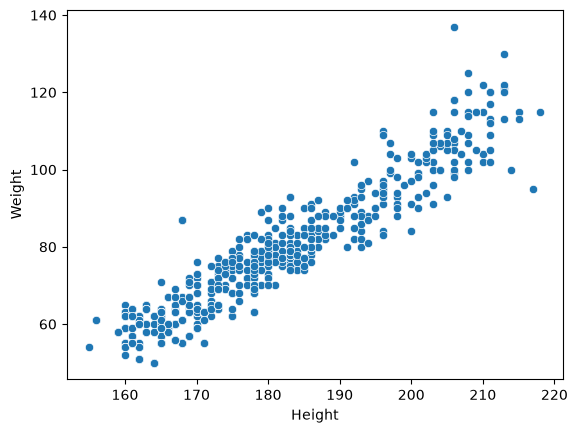

In [ ]:
sns.scatterplot(athletes, x='Height', y='Weight')

<Axes: xlabel='Height', ylabel='Weight'>

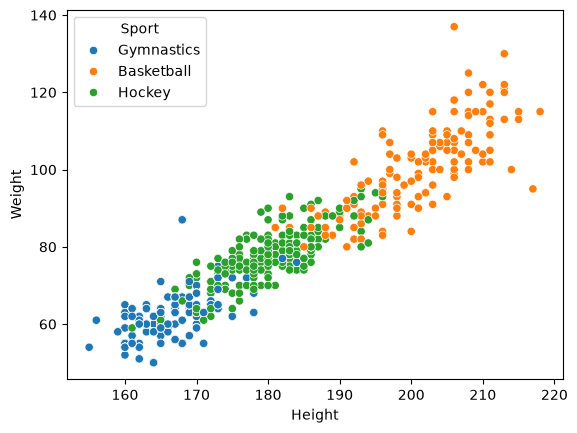

In [7]:
sns.scatterplot(athletes, x='Height', y='Weight', hue='Sport')

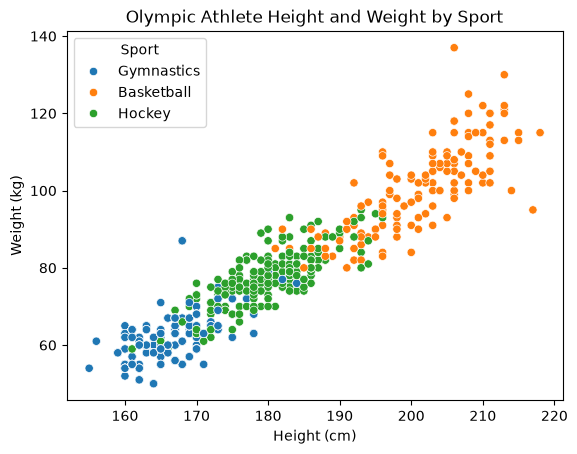

In [8]:
sns.scatterplot(athletes, x='Height', y='Weight', hue='Sport')
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('Olympic Athlete Height and Weight by Sport')
plt.show()

# Line Plots

In [9]:
athletes_line = duckdb.sql("""SELECT Year, AVG(Height) AS Avg_Height
                        FROM olympics
                        WHERE Season = 'Summer' AND Sport = 'Basketball'
                        GROUP BY Year
                        ORDER BY Year ASC""").df()

athletes_line.head()

,Year,Avg_Height
0,1936,182.574074
1,1948,185.550725
2,1952,187.600000
3,1956,186.952941
4,1960,188.317708


<Axes: xlabel='Year', ylabel='Avg_Height'>

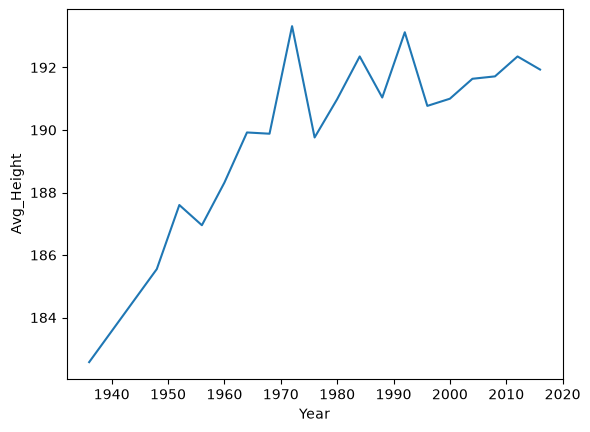

In [10]:
sns.lineplot(athletes_line, x='Year', y='Avg_Height')

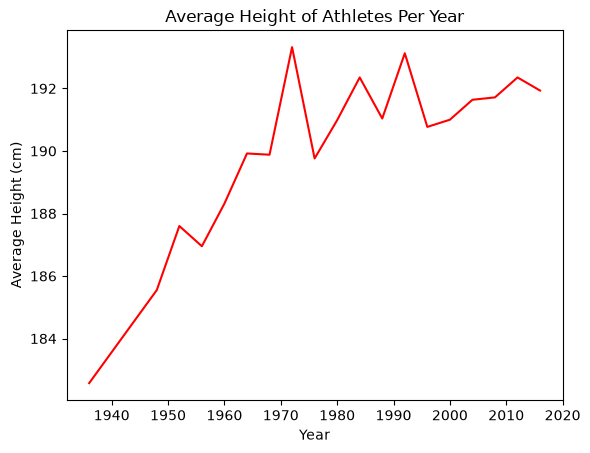

In [16]:
sns.lineplot(athletes_line, x='Year', y='Avg_Height', color='red')
plt.ylabel('Average Height (cm)')
plt.title('Average Height of Athletes Per Year')
plt.show()

# Bar Chart

In [23]:
athletes_hist = duckdb.sql("""SELECT Team, COUNT(*) AS medals
                            FROM olympics
                            WHERE Season = 'Summer' AND Year = 2012 AND Medal = 'Gold'
                            GROUP BY Team
                            ORDER BY medals DESC
                            LIMIT 10""").df()

athletes_hist.head()

,Team,medals
0,United States,139
1,China,50
2,Russia,50
3,Great Britain,46
4,Germany,43


<Axes: xlabel='Team', ylabel='medals'>

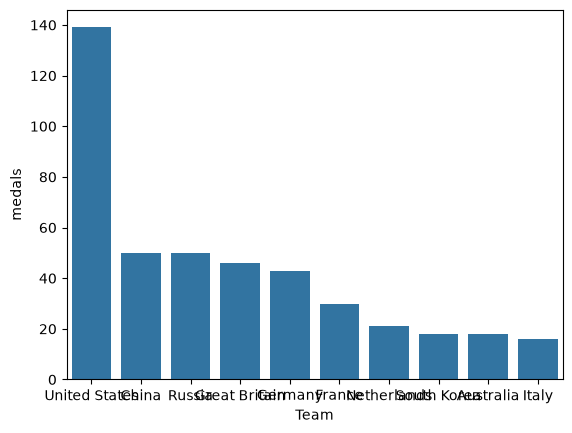

In [24]:
sns.barplot(athletes_hist, x='Team', y='medals')

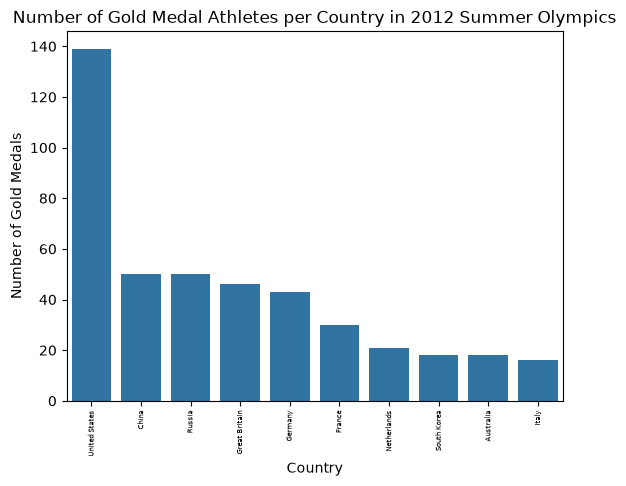

In [27]:
sns.barplot(athletes_hist, x='Team', y='medals')
plt.xticks(rotation=90, fontsize=5)
plt.ylabel('Number of Gold Medals')
plt.xlabel('Country')
plt.title('Number of Gold Medal Athletes per Country in 2012 Summer Olympics')
plt.show()

<Axes: xlabel='Age', ylabel='Count'>

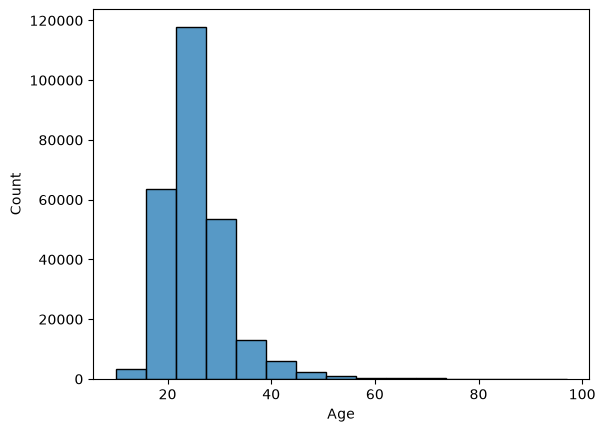

In [29]:
# histogram
sns.histplot(olympics, x='Age', bins=15)

In [44]:
athletes_dash = duckdb.sql("""SELECT *
                            FROM olympics
                            WHERE Games = '2016 Summer' AND Sex = 'M' AND Sport = 'Athletics' AND Event LIKE '% 100 metres%'
                            """).df()

Text(0, 0.5, 'Weight (kg)')

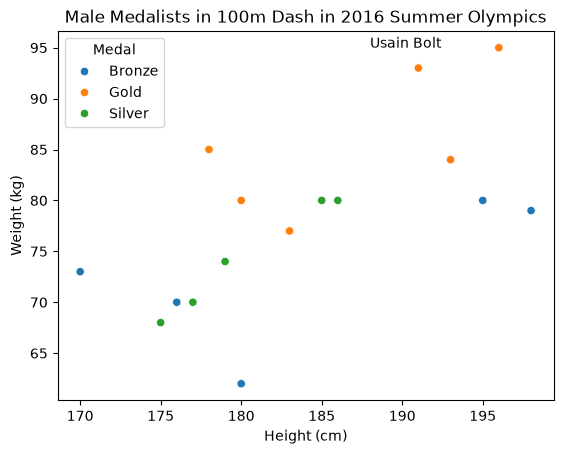

In [46]:
sns.scatterplot(athletes_dash, x='Height', y='Weight', hue='Medal')
plt.annotate(text='Usain Bolt', xy=(188,95))
plt.title('Male Medalists in 100m Dash in 2016 Summer Olympics')
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')

# Plotly

In [51]:
dream_team = duckdb.sql("""SELECT *
                            FROM olympics
                            WHERE Sex = 'M' AND Sport = 'Basketball' AND Year = 1992 AND Team = 'United States'""").df()

dream_team.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,7901,Charles Wade Barkley,M,29.0,198.0,114.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
1,11668,Larry Joe Bird,M,35.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
2,30009,Clyde Austin Drexler,M,30.0,200.0,101.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
3,33553,Patrick Aloysius Ewing,M,29.0,213.0,109.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
4,55424,"Earvin ""Magic"" Johnson, Jr.",M,32.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold


In [52]:
fig = px.scatter(dream_team, x='Height', y='Weight', text='Name', width=800, height=500)
fig.update_layout(title='1992 Dream Team Players Weights and Heights', 
                  xaxis_title='Height (cm)', 
                  yaxis_title='Weight (kg)')

fig.show()